# 01 · De la pregunta a una respuesta fundamentada

Un modelo de lenguaje responde con lo que memorizó durante su entrenamiento. Nunca ha leído **tus** documentos,
no puede saber qué cambió la semana pasada y, cuando no sabe, a menudo se inventa algo que suena bien.
La **generación aumentada por recuperación (RAG, por sus siglas en inglés)** lo arregla dividiendo el trabajo en dos:
primero *encontrar* los pasajes que importan y después pedirle al modelo que responda *usando solo esos pasajes* y que
diga de dónde sale cada afirmación.

Este primer módulo construye el sistema RAG completo más pequeño posible, con Python casi puro y NumPy, y mide cada
paso. No se llama a ningún modelo ni hace falta ninguna clave: el objetivo es ver las piezas en movimiento y dónde
fallan, antes de que los frameworks las escondan.

**Aprenderás**
1. La anatomía de un sistema RAG y de qué es responsable cada parte
2. El troceado: por qué *dónde* cortas los documentos decide si la respuesta llega a poder encontrarse, medido
3. Recuperación léxica con BM25, escrita desde cero
4. Cómo medir la recuperación con honestidad: hit@k y rango recíproco medio (MRR) sobre una batería de preguntas
5. Respuestas fundamentadas con citas, y negarse a responder cuando los documentos callan
6. Los modos de fallo que corrigen los módulos siguientes

## 1. La anatomía de un sistema RAG

```
  documentos ──► trocear ──► indexar ────────┐              (se hace una vez, sin conexión)
                                             ▼
  pregunta ──► recuperar los k mejores ──► armar el prompt ──► generar ──► respuesta + citas
                    ▲                                              │
                    └──────────── evaluar y mejorar ◄──────────────┘   (se hace de forma continua)
```

| Etapa | Pregunta a la que responde | Fallo típico |
|---|---|---|
| **Trocear** | ¿Cuál es la unidad de texto que podemos encontrar y citar? | El dato queda cortado por la mitad, o enterrado en un trozo enorme |
| **Indexar / recuperar** | ¿Qué trozos son relevantes para esta pregunta? | El trozo correcto existe pero no está entre los *k* primeros |
| **Prompt** | ¿Qué ve el modelo? | Demasiados trozos, ruido, contradicciones |
| **Generar** | ¿Puede responder *solo* con lo que se le dio? | Añade datos de memoria, o ignora los trozos |
| **Evaluar** | ¿Es correcta y, si no lo es, por qué? | Nadie mira, así que nada mejora |

El resto del curso son estas cinco etapas, en este orden, y termina con un sistema que se evalúa a sí mismo y
devuelve sus propios errores a la documentación.

### Imagen: las cinco etapas y dónde falla cada una

Lee la imagen de izquierda a derecha. La fila de arriba es el camino de una pregunta. Las cajas rojas de debajo
son el fallo típico de cada etapa, y por eso el curso mide cada etapa por separado en lugar de juzgar solo la
respuesta final.

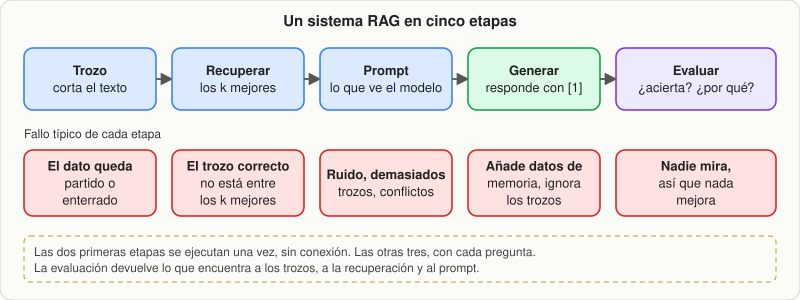

In [1]:
from IPython.display import SVG, display
import html as _h

_COL = {  # fill, stroke  (light cards with dark text: readable in light and dark themes)
    "gold": ("#fff4c2", "#b89d28"), "blue": ("#dbeafe", "#3b82f6"), "green": ("#dcfce7", "#16a34a"),
    "red": ("#fee2e2", "#dc2626"), "grey": ("#f1f1f4", "#8a8aa0"), "violet": ("#ede9fe", "#7c3aed"),
}

def diagram(width, height, items, title=None):
    # items: ("box", x, y, w, h, "text\nmore text", colour) | ("arrow", x1, y1, x2, y2, "label") |
    #        ("text", x, y, "text", size, "start|middle|end") | ("note", x, y, w, h, "text")
    out = [f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" width="100%" '
           f'font-family="Helvetica, Arial, sans-serif">',
           '<defs><marker id="ah" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" '
           'orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 z" fill="#555"/></marker></defs>',
           f'<rect width="{width}" height="{height}" rx="12" fill="#fbfbf8" stroke="#d8d8cf"/>']
    if title:
        out.append(f'<text x="{width / 2}" y="26" text-anchor="middle" font-size="15" font-weight="700" fill="#222">{_h.escape(title)}</text>')
    for it in items:
        kind = it[0]
        if kind == "box":
            _, x, y, w, h, text, col = it
            fill, stroke = _COL[col]
            out.append(f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="9" fill="{fill}" stroke="{stroke}" stroke-width="1.6"/>')
            lines = text.split("\n")
            y0 = y + h / 2 - (len(lines) - 1) * 8.5 + 4.5
            for k, ln in enumerate(lines):
                bold = ' font-weight="700"' if k == 0 and len(lines) > 1 else ""
                out.append(f'<text x="{x + w / 2}" y="{y0 + k * 17}" text-anchor="middle" font-size="13" fill="#222"{bold}>{_h.escape(ln)}</text>')
        elif kind == "arrow":
            _, x1, y1, x2, y2, label = it
            out.append(f'<line x1="{x1}" y1="{y1}" x2="{x2}" y2="{y2}" stroke="#555" stroke-width="1.8" marker-end="url(#ah)"/>')
            if label:
                out.append(f'<text x="{(x1 + x2) / 2}" y="{(y1 + y2) / 2 - 6}" text-anchor="middle" font-size="11.5" fill="#555">{_h.escape(label)}</text>')
        elif kind == "text":
            _, x, y, text, size, anchor = it
            for k, ln in enumerate(text.split("\n")):
                out.append(f'<text x="{x}" y="{y + k * (size + 4)}" text-anchor="{anchor}" font-size="{size}" fill="#333">{_h.escape(ln)}</text>')
        elif kind == "note":
            _, x, y, w, h, text = it
            out.append(f'<rect x="{x}" y="{y}" width="{w}" height="{h}" rx="6" fill="none" stroke="#b89d28" stroke-dasharray="5 4"/>')
            for k, ln in enumerate(text.split("\n")):
                out.append(f'<text x="{x + 10}" y="{y + 20 + k * 16}" font-size="12" fill="#444">{_h.escape(ln)}</text>')
    out.append("</svg>")
    display(SVG("".join(out)))


diagram(800, 300, [
    ("box", 24, 48, 132, 62, "Trozo\ncorta el texto", "blue"),
    ("arrow", 156, 79, 172, 79, ""),
    ("box", 172, 48, 132, 62, "Recuperar\nlos k mejores", "blue"),
    ("arrow", 304, 79, 320, 79, ""),
    ("box", 320, 48, 132, 62, "Prompt\nlo que ve el modelo", "blue"),
    ("arrow", 452, 79, 468, 79, ""),
    ("box", 468, 48, 132, 62, "Generar\nresponde con [1]", "green"),
    ("arrow", 600, 79, 616, 79, ""),
    ("box", 616, 48, 160, 62, "Evaluar\n¿acierta? ¿por qué?", "violet"),
    ("text", 24, 138, "Fallo típico de cada etapa", 12, "start"),
    ("box", 24, 150, 132, 66, "El dato queda\npartido o\nenterrado", "red"),
    ("box", 172, 150, 132, 66, "El trozo correcto\nno está entre\nlos k mejores", "red"),
    ("box", 320, 150, 132, 66, "Ruido, demasiados\ntrozos, conflictos", "red"),
    ("box", 468, 150, 132, 66, "Añade datos de\nmemoria, ignora\nlos trozos", "red"),
    ("box", 616, 150, 160, 66, "Nadie mira,\nasí que nada\nmejora", "red"),
    ("note", 24, 236, 752, 46, "Las dos primeras etapas se ejecutan una vez, sin conexión. Las otras tres, con cada pregunta.\nLa evaluación devuelve lo que encuentra a los trozos, a la recuperación y al prompt."),
], "Un sistema RAG en cinco etapas")

## 2. El corpus

Todos los notebooks de este curso usan el mismo conjunto pequeño y ficticio de documentos: el manual de operaciones de
un parque eólico marino, *Harbourview*. Se escribió para el curso, así que no tiene licencia, ni contenido confidencial,
ni ninguna empresa real. Tiene 22 pasajes cortos y cada uno contiene varios datos comprobables (un límite de oleaje,
un plazo, un número de piezas). También tenemos 16 preguntas con respuesta conocida, dos de las cuales el manual no
puede responder a propósito.

Un corpus pequeño es una ventaja aquí: puedes leerlo entero, así que cuando la recuperación falla puedes ver *por qué*.
El corpus se queda en inglés a propósito: son los datos, no la explicación.

In [2]:
# El manual de Harbourview: 22 pasajes, ficticios, escritos para este curso
PASSAGES = [
    ["p01", "Safety / Access", "Technicians must hold a valid GWO Basic Safety Training certificate before boarding a crew transfer vessel. Certificates are checked at the harbour gate and expire after two years."],
    ["p02", "Safety / Weather limits", "Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed at the harbour exceeds 20 m/s. The duty coordinator decides at 06:00 and may cancel later."],
    ["p03", "Safety / Lone working", "Lone working inside a nacelle is forbidden. Every task inside a turbine needs at least two people, and both must carry a personal locator beacon."],
    ["p04", "Turbines / Specification", "Each of the 40 turbines is rated at 8.0 MW with a rotor diameter of 164 m. Cut-in wind speed is 3 m/s, rated speed is 12.5 m/s and cut-out speed is 25 m/s."],
    ["p05", "Turbines / Naming", "Turbines are named HV01 to HV40, numbered from the western edge of the array. The offshore substation is OSS1, in the centre."],
    ["p06", "Maintenance / Schedule", "Every turbine gets a planned service once a year between April and September. The service takes two technicians about two days, plus weather delays."],
    ["p07", "Maintenance / Gearbox oil", "Gearbox oil is sampled every six months. If the particle count exceeds ISO 4406 code 18/16/13, a filter change is scheduled within 14 days."],
    ["p08", "Maintenance / Blade inspection", "Blades are inspected by drone every 12 months and after any lightning alarm. Leading-edge erosion above grade 3 is repaired in the next planned service."],
    ["p09", "Faults / Alarm levels", "Alarms have three levels. Level 1 is informational. Level 2 needs a remote check within 4 hours. Level 3 stops the turbine and needs a site visit within 24 hours when the weather allows."],
    ["p10", "Faults / Pitch system", "A pitch system fault (code PF-203) usually means a low accumulator pressure. Reset it remotely once. If it returns within 48 hours, send a crew to replace the hydraulic accumulator."],
    ["p11", "Faults / Yaw misalignment", "A yaw error above 8 degrees for more than 10 minutes raises alarm YW-110. Persistent errors point to a faulty wind vane: the vane is recalibrated, then replaced if the error remains."],
    ["p12", "Faults / Grid loss", "On loss of grid connection the turbines stop and the converters isolate. Restart is allowed only when the grid operator confirms voltage within 5% of nominal for 10 minutes."],
    ["p13", "Environment / Marine mammals", "Piling and heavy cable work pause when a marine mammal is sighted within 500 m. Work resumes after 30 minutes without a sighting."],
    ["p14", "Environment / Bird collision", "Between October and March, turbines HV01 to HV08 are curtailed at night during the peak migration periods announced by the ornithology team."],
    ["p15", "Environment / Waste", "Used oil, filters and composite offcuts are brought ashore and logged in the waste register. Nothing is discharged at sea."],
    ["p16", "Logistics / Spare parts", "The harbour warehouse keeps the critical spares: two pitch accumulators, four wind vanes and a spare converter module. Reorder when stock falls below one unit."],
    ["p17", "Logistics / Helicopter", "A helicopter is used only for medical evacuation and for urgent Level 3 visits when vessels cannot sail. Booking goes through the duty coordinator."],
    ["p18", "Contacts / Duty coordinator", "The duty coordinator is reachable 24 hours a day on the control room line. Out-of-hours safety incidents are reported there first."],
    ["p19", "Reporting / Incidents", "Any injury or near miss is reported within one hour and a written report is filed within 24 hours. Environmental incidents follow the same deadlines."],
    ["p20", "Reporting / Performance", "Availability is reported monthly. The target is 97% time-based availability, counting weather downtime as available."],
    ["p21", "Grid / Export", "Power is exported at 66 kV through two cables to the onshore substation. The export limit agreed with the grid operator is 300 MW."],
    ["p22", "Training / Induction", "New staff complete a two-day induction covering the handbook, emergency drills and the sea survival course before their first transfer."],
]

# (id, pregunta, pasaje correcto, dato que debe contener la respuesta); None = el manual no lo dice
QUESTIONS = [
    ["q01", "What wave height stops the crew boats from sailing?", "p02", "1.5 m"],
    ["q02", "How often is the gearbox oil sampled?", "p07", "six months"],
    ["q03", "Who may work alone inside a nacelle?", "p03", "forbidden"],
    ["q04", "What is the rotor diameter of a turbine?", "p04", "164 m"],
    ["q05", "What do I do if the pitch fault comes back after a reset?", "p10", "replace the hydraulic accumulator"],
    ["q06", "When must a Level 3 alarm be attended on site?", "p09", "24 hours"],
    ["q07", "How soon must an injury be reported?", "p19", "one hour"],
    ["q08", "What is the largest amount of power the farm is allowed to send ashore?", "p21", "300 MW"],
    ["q09", "Which turbines are switched off at night in the autumn to protect birds?", "p14", "HV01 to HV08"],
    ["q10", "How many spare wind vanes are kept in stock?", "p16", "four wind vanes"],
    ["q11", "What qualification do I need before getting on the boat?", "p01", "GWO Basic Safety Training"],
    ["q12", "When can the turbines restart after a blackout?", "p12", "10 minutes"],
    ["q13", "When can a helicopter be used?", "p17", "medical evacuation"],
    ["q14", "What happens when a dolphin is seen near the piling work?", "p13", "pause"],
    ["q15", "What is the price of electricity per MWh?", None, None],
    ["q16", "Who is the chief executive of the operating company?", None, None],
]

In [3]:
import re, math, textwrap
import numpy as np
import matplotlib.pyplot as plt

print(len(PASSAGES), "passages,", sum(len(t.split()) for _, _, t in PASSAGES), "words in total")
print(len(QUESTIONS), "questions,", sum(q[2] is None for q in QUESTIONS), "of them unanswerable by design\n")
for pid, section, text in PASSAGES[:3]:
    print(f"[{pid}] {section}\n    {textwrap.fill(text, 100, subsequent_indent='    ')}\n")

22 passages, 560 words in total
16 questions, 2 of them unanswerable by design

[p01] Safety / Access
    Technicians must hold a valid GWO Basic Safety Training certificate before boarding a crew transfer
    vessel. Certificates are checked at the harbour gate and expire after two years.

[p02] Safety / Weather limits
    Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed
    at the harbour exceeds 20 m/s. The duty coordinator decides at 06:00 and may cancel later.

[p03] Safety / Lone working
    Lone working inside a nacelle is forbidden. Every task inside a turbine needs at least two people,
    and both must carry a personal locator beacon.



~/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## 3. Troceado: dónde cortas decide qué se puede encontrar

El manual llega como un único texto largo, no como 22 pasajes ordenados. El divisor más simple corta cada *N*
caracteres. Es rápido y no necesita entender el documento, y así empiezan muchos primeros prototipos. Su defecto es que
un corte puede caer en mitad de la frase que contiene la respuesta.

Podemos medirlo. Para cada pregunta con respuesta conocemos el dato que debe contener (por ejemplo `1.5 m`). Un troceado
es *bueno para esa pregunta* cuando la **frase completa que enuncia el dato** sobrevive dentro de un único trozo: un
trozo que contiene `1.5 m` pero perdió *"...do not sail when the wave height exceeds"* no sirve como evidencia.
(Comprobar solo el número favorecería a todas las estrategias.)

In [4]:
handbook = "\n\n".join(f"{section}\n{text}" for _, section, text in PASSAGES)
print(len(handbook), "characters in the handbook")

def fixed_chunks(text, size, overlap=0):
    step = size - overlap
    return [text[i:i + size] for i in range(0, max(len(text) - overlap, 1), step)]

def section_chunks(text):
    return [block for block in text.split("\n\n") if block.strip()]

def sentence_chunks(text, per_chunk=2):
    sentences = re.split(r"(?<=[.!?])\s+", text.replace("\n\n", " "))
    return [" ".join(sentences[i:i + per_chunk]) for i in range(0, len(sentences), per_chunk)]

all_sentences = [s for _, _, t in PASSAGES for s in re.split(r"(?<=[.!?])\s+", t)]
# la frase completa que enuncia cada dato de respuesta
fact_sentences = [next(s for s in all_sentences if q[3] in s) for q in QUESTIONS if q[3]]

def fact_survival(chunks):
    # proporción de frases de dato que aparecen enteras dentro de un único trozo
    return sum(any(s in c for c in chunks) for s in fact_sentences) / len(fact_sentences)

strategies = {
    "fixed 200 chars":               fixed_chunks(handbook, 200),
    "fixed 200 chars, overlap 50":   fixed_chunks(handbook, 200, 50),
    "fixed 400 chars":               fixed_chunks(handbook, 400),
    "2 sentences":                   sentence_chunks(handbook, 2),
    "by section (the document's own structure)": section_chunks(handbook),
}
print(f"{'strategy':44s}{'chunks':>8s}{'mean chars':>12s}{'sentences kept whole':>22s}")
for name, ch in strategies.items():
    print(f"{name:44s}{len(ch):8d}{np.mean([len(c) for c in ch]):12.0f}{fact_survival(ch):22.0%}")

3862 characters in the handbook
strategy                                      chunks  mean chars  sentences kept whole
fixed 200 chars                                   20         193                   71%
fixed 200 chars, overlap 50                       26         197                   86%
fixed 400 chars                                   10         386                   86%
2 sentences                                       23         166                  100%
by section (the document's own structure)         22         174                  100%


Los cortes ciegos de tamaño fijo rompen una parte de las frases de respuesta, y el solapamiento rescata parte de ellas
a cambio de más texto repetido. Cortar siguiendo la estructura propia del documento conserva cada frase entera **y**
hace que cada trozo sea una unidad que una persona reconocería (una sección), lo que además te da una cita natural:
*Safety / Weather limits*. (Lee las cifras exactas en la tabla de arriba; dependen de dónde caigan los cortes.)

**Regla práctica:** usa la estructura que ya existe (encabezados, secciones, filas, párrafos) antes de recurrir a un
número de caracteres. Cuando no hay estructura, usa ventanas con conciencia de frase y con solapamiento. El tamaño es un
compromiso: los trozos pequeños recuperan con precisión pero pierden contexto; los grandes conservan el contexto pero
diluyen la coincidencia y cuestan más tokens de prompt. Mantenemos la sección como trozo durante el resto del curso.

## 4. Recuperación léxica con BM25

La idea de recuperación buena más antigua es también la línea base simple más fuerte: **ordenar los trozos según las
palabras de la pregunta que contienen**, dando más peso a las palabras raras (*accumulator*) que a las comunes (*the*).
**BM25** es la forma estándar de hacerlo: una puntuación de frecuencia de término que se satura (la décima repetición de
una palabra aporta poco) y se normaliza por la longitud del trozo, multiplicada por un peso de frecuencia inversa de
documento (IDF).

$$\text{score}(q,d)=\sum_{t\in q}\text{IDF}(t)\cdot\frac{f(t,d)\,(k_1+1)}{f(t,d)+k_1\,(1-b+b\,|d|/\overline{|d|})}$$

Aquí tienes una implementación completa. Los buscadores han funcionado con esta fórmula durante décadas, y es lo que
usó la búsqueda de Social Pulse de este proyecto para su recuperación.

In [5]:
STOP = set("a an and are as at be by can do does for from how i if in is it of on or that the this to what when which who with you".split())

def tokens(text):
    return [w for w in re.findall(r"[a-z0-9]+", text.lower()) if w not in STOP]

class BM25:
    def __init__(self, docs, k1=1.5, b=0.75):
        self.k1, self.b = k1, b
        self.tf = [{} for _ in docs]
        for i, d in enumerate(docs):
            for t in tokens(d):
                self.tf[i][t] = self.tf[i].get(t, 0) + 1
        self.len = np.array([sum(tf.values()) for tf in self.tf], dtype=float)
        self.avg = self.len.mean()
        df = {}
        for tf in self.tf:
            for t in tf:
                df[t] = df.get(t, 0) + 1
        n = len(docs)
        self.idf = {t: math.log(1 + (n - c + 0.5) / (c + 0.5)) for t, c in df.items()}

    def scores(self, query):
        s = np.zeros(len(self.tf))
        for t in set(tokens(query)):
            if t not in self.idf:
                continue
            for i, tf in enumerate(self.tf):
                f = tf.get(t, 0)
                if f:
                    s[i] += self.idf[t] * f * (self.k1 + 1) / (f + self.k1 * (1 - self.b + self.b * self.len[i] / self.avg))
        return s

chunks = [f"{section}. {text}" for _, section, text in PASSAGES]    # el título de la sección también es buscable
ids = [p[0] for p in PASSAGES]
bm25 = BM25(chunks)

def search(index, query, k=3):
    s = index.scores(query)
    order = np.argsort(-s)[:k]
    return [(ids[i], float(s[i])) for i in order]

q = "What wave height stops the crew boats from sailing?"
print(q)
for pid, score in search(bm25, q):
    print(f"  {score:5.2f}  [{pid}] {chunks[ids.index(pid)][:90]}...")

What wave height stops the crew boats from sailing?
   6.30  [p02] Safety / Weather limits. Crew transfer vessels do not sail when the significant wave heigh...
   2.34  [p09] Faults / Alarm levels. Alarms have three levels. Level 1 is informational. Level 2 needs a...
   1.81  [p01] Safety / Access. Technicians must hold a valid GWO Basic Safety Training certificate befor...


## 5. Medir la recuperación con honestidad

"Parece que funciona" no es una medición. Tenemos 14 preguntas con respuesta y un pasaje correcto conocido, así que
podemos calcular:

* **hit@k**: la proporción de preguntas cuyo pasaje correcto está entre los *k* primeros resultados. hit@1 es el
  criterio estricto; hit@3 es lo que importa cuando el generador recibe tres pasajes.
* **MRR** (rango recíproco medio): el promedio de 1/posición del pasaje correcto (1 si es el primero, 0.5 si es el
  segundo, 0 si no está en la lista). Premia poner el pasaje correcto más arriba, no solo en algún lugar.

Informa siempre estas cifras sobre preguntas con las que el sistema **no** se ajustó.

In [6]:
answerable = [q for q in QUESTIONS if q[2]]

def evaluate(index, k=3, verbose=False):
    ranks = []
    for qid, question, gold, _ in answerable:
        order = [pid for pid, _ in search(index, question, k=len(ids))]
        rank = order.index(gold) + 1
        ranks.append(rank)
        if verbose and rank > 1:
            print(f"  {qid} gold {gold} ranked {rank}: {question}")
    ranks = np.array(ranks)
    return dict(hit1=(ranks == 1).mean(), hit3=(ranks <= 3).mean(), mrr=(1 / ranks).mean()), ranks

metrics, ranks = evaluate(bm25, verbose=True)
print({k: round(float(v), 3) for k, v in metrics.items()})

  q08 gold p21 ranked 2: What is the largest amount of power the farm is allowed to send ashore?
  q11 gold p01 ranked 2: What qualification do I need before getting on the boat?
{'hit1': 0.857, 'hit3': 1.0, 'mrr': 0.929}


BM25 pone primero el pasaje correcto en la mayoría de las preguntas sin ajustes, y por eso es una línea base que
conviene ejecutar siempre antes de algo más sofisticado. Ahora lee las que no puso primero junto a su pasaje correcto:
*"send ashore"* frente a *"exported ... to the onshore substation"*, y *"qualification"* frente a *"certificate"*. El
autor y quien pregunta usaron palabras distintas para la misma idea.

Esa es la debilidad que define a la búsqueda léxica: **empareja palabras, no significado.** Si quien pregunta usa
palabras distintas a las del autor, el pasaje correcto puede perder frente a uno que solo comparte una palabra común.
Cuenta las palabras que cada pregunta comparte con su pasaje correcto para verlo.

In [7]:
for qid, question, gold, _ in answerable:
    q_terms = set(tokens(question))
    p_terms = set(tokens(chunks[ids.index(gold)]))
    overlap = q_terms & p_terms
    top = search(bm25, question, k=1)[0][0]
    flag = "" if top == gold else "   <-- missed"
    print(f"{qid}: {len(overlap)} shared words with its gold passage {sorted(overlap)}{flag}")

q01: 3 shared words with its gold passage ['crew', 'height', 'wave']
q02: 3 shared words with its gold passage ['gearbox', 'oil', 'sampled']
q03: 2 shared words with its gold passage ['inside', 'nacelle']
q04: 2 shared words with its gold passage ['diameter', 'rotor']
q05: 3 shared words with its gold passage ['fault', 'pitch', 'reset']
q06: 4 shared words with its gold passage ['3', 'alarm', 'level', 'site']
q07: 2 shared words with its gold passage ['injury', 'reported']
q08: 1 shared words with its gold passage ['power']   <-- missed
q09: 2 shared words with its gold passage ['night', 'turbines']
q10: 4 shared words with its gold passage ['spare', 'stock', 'vanes', 'wind']
q11: 1 shared words with its gold passage ['before']   <-- missed
q12: 2 shared words with its gold passage ['restart', 'turbines']
q13: 2 shared words with its gold passage ['helicopter', 'used']
q14: 2 shared words with its gold passage ['piling', 'work']


### Imagen: una pregunta a través del sistema que hemos construido

Este es el camino de la primera pregunta de la batería por el código de las secciones 4 a 6, con los números que
imprime el notebook. Sigue las flechas: BM25 puntúa cada trozo, se conservan los tres primeros, la comprobación de
rechazo compara la mejor puntuación con el umbral y solo entonces se elige una frase y se cita.

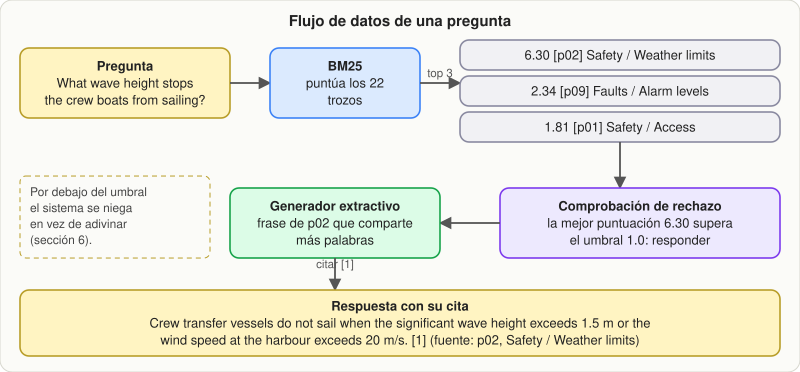

In [8]:
diagram(800, 372, [
    ("box", 20, 48, 210, 70, "Pregunta\nWhat wave height stops\nthe crew boats from sailing?", "gold"),
    ("arrow", 230, 83, 270, 83, ""),
    ("box", 270, 48, 150, 70, "BM25\npuntúa los 22\ntrozos", "blue"),
    ("arrow", 420, 83, 460, 83, "top 3"),
    ("box", 460, 40, 320, 30, "6.30   [p02] Safety / Weather limits", "grey"),
    ("box", 460, 76, 320, 30, "2.34   [p09] Faults / Alarm levels", "grey"),
    ("box", 460, 112, 320, 30, "1.81   [p01] Safety / Access", "grey"),
    ("arrow", 620, 142, 620, 188, ""),
    ("box", 500, 188, 280, 70, "Comprobación de rechazo\nla mejor puntuación 6.30 supera\nel umbral 1.0: responder", "violet"),
    ("arrow", 500, 223, 440, 223, ""),
    ("box", 230, 188, 210, 70, "Generador extractivo\nfrase de p02 que comparte\nmás palabras", "green"),
    ("arrow", 335, 258, 335, 290, "citar [1]"),
    ("note", 20, 176, 190, 82, "Por debajo del umbral\nel sistema se niega\nen vez de adivinar\n(sección 6)."),
    ("box", 20, 290, 760, 66, "Respuesta con su cita\nCrew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the\nwind speed at the harbour exceeds 20 m/s. [1]   (fuente: p02, Safety / Weather limits)", "gold"),
], "Flujo de datos de una pregunta")

## 6. Generar una respuesta fundamentada, o negarse

El generador es la parte que, en producción, es un modelo de lenguaje: *responde la pregunta usando solo estos pasajes
numerados, cítalos como [1], [2] y di que no lo encuentras si la respuesta no está.* Los notebooks 03 y 04 conectan un
modelo real. Aquí usamos un sustituto **extractivo** deliberadamente simple: devuelve la frase del pasaje principal que
comparte más palabras con la pregunta. Basta para mostrar los dos comportamientos que más importan:

1. **Citas**: toda respuesta apunta al pasaje del que salió, para que un lector pueda comprobarla.
2. **Rechazo**: cuando la mejor puntuación es demasiado baja, di *"no está en el manual"* en lugar de adivinar. Un
   sistema RAG que nunca se niega responderá la pregunta sobre el director ejecutivo con el pasaje menos malo.

¿Dónde ponemos el umbral de rechazo? A partir de los datos, no a ojo: compara la puntuación máxima en las preguntas que
el manual puede responder con la de las que no.

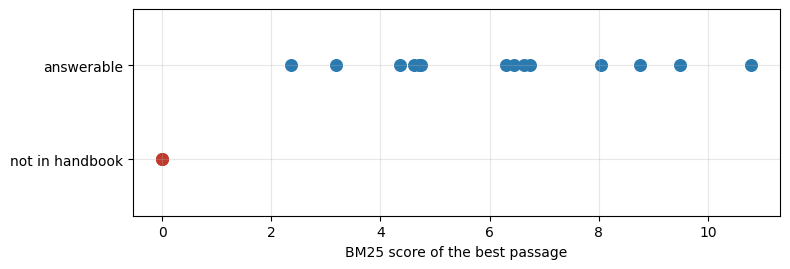

answerable: min 2.36 median 6.37 | unanswerable: max 0.00


In [9]:
top_scores = {qid: search(bm25, question, k=1)[0][1] for qid, question, gold, _ in QUESTIONS}
ans_scores = [top_scores[q[0]] for q in QUESTIONS if q[2]]
no_scores = [top_scores[q[0]] for q in QUESTIONS if not q[2]]

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.scatter(ans_scores, np.ones(len(ans_scores)), s=70, label="answerable", color="#2a7ab0")
ax.scatter(no_scores, np.zeros(len(no_scores)), s=70, label="not in the handbook", color="#c0392b")
ax.set_yticks([0, 1], ["not in handbook", "answerable"]); ax.set_xlabel("BM25 score of the best passage")
ax.set_ylim(-0.6, 1.6); ax.grid(alpha=.3); plt.tight_layout(); plt.show()
print("answerable: min %.2f median %.2f | unanswerable: max %.2f" % (min(ans_scores), np.median(ans_scores), max(no_scores)))

In [10]:
THRESHOLD = 1.0     # del gráfico de arriba: el hueco entre las puntuaciones sin respuesta (0) y la respuesta más débil

def sentences(text):
    return re.split(r"(?<=[.!?])\s+", text)

def answer(index, question, k=2, threshold=THRESHOLD):
    hits = search(index, question, k)
    if hits[0][1] < threshold:
        return "I cannot find that in the handbook.", []
    pid = hits[0][0]
    section, text = chunks[ids.index(pid)].split(". ", 1)
    q_terms = set(tokens(question))
    best = max(sentences(text), key=lambda s: len(q_terms & set(tokens(s))))
    return f"{best} [1]", [(1, pid, section)]

for qid, question, gold, fact in QUESTIONS:
    text, cites = answer(bm25, question)
    cite = f"   (source: {cites[0][1]}, {cites[0][2]})" if cites else ""
    print(f"{qid} {question}\n    -> {text}{cite}\n")

q01 What wave height stops the crew boats from sailing?
    -> Crew transfer vessels do not sail when the significant wave height exceeds 1.5 m or the wind speed at the harbour exceeds 20 m/s. [1]   (source: p02, Safety / Weather limits)

q02 How often is the gearbox oil sampled?
    -> Gearbox oil is sampled every six months. [1]   (source: p07, Maintenance / Gearbox oil)

q03 Who may work alone inside a nacelle?
    -> Lone working inside a nacelle is forbidden. [1]   (source: p03, Safety / Lone working)

q04 What is the rotor diameter of a turbine?
    -> Each of the 40 turbines is rated at 8.0 MW with a rotor diameter of 164 m. [1]   (source: p04, Turbines / Specification)

q05 What do I do if the pitch fault comes back after a reset?
    -> A pitch system fault (code PF-203) usually means a low accumulator pressure. [1]   (source: p10, Faults / Pitch system)

q06 When must a Level 3 alarm be attended on site?
    -> Level 3 stops the turbine and needs a site visit within 24 hours 

## 7. Calificar las respuestas y qué dicen los números

Que la recuperación acierte no significa todavía que la respuesta sea correcta, así que califica también el resultado
final. Una respuesta cuenta como **correcta** si contiene el dato requerido, como **rechazada correctamente** cuando la
pregunta no tiene respuesta y el sistema lo dice, y como **incorrecta** en cualquier otro caso (responder una pregunta
sin respuesta es el peor caso: una invención con aplomo).

In [11]:
def grade(index, threshold=THRESHOLD):
    out = {"correct": 0, "wrong: retrieval missed the passage": 0, "wrong: right passage, wrong sentence": 0,
           "missed (refused but answerable)": 0, "correctly refused": 0, "invented (answered, unanswerable)": 0}
    for qid, question, gold, fact in QUESTIONS:
        text, cites = answer(index, question, threshold=threshold)
        refused = not cites
        if gold:
            if refused:
                out["missed (refused but answerable)"] += 1
            elif fact in text:
                out["correct"] += 1
            else:
                out["wrong: retrieval missed the passage" if cites[0][1] != gold else "wrong: right passage, wrong sentence"] += 1
                print(f"  wrong: {qid} -> {text}")
        else:
            out["correctly refused" if refused else "invented (answered, unanswerable)"] += 1
    return out

print("with the threshold at", THRESHOLD)
for k, v in grade(bm25).items():
    print(f"{k:42s}{v:3d}")

with the threshold at 1.0
  wrong: q05 -> A pitch system fault (code PF-203) usually means a low accumulator pressure. [1]
  wrong: q08 -> Used oil, filters and composite offcuts are brought ashore and logged in the waste register. [1]
  wrong: q11 -> New staff complete a two-day induction covering the handbook, emergency drills and the sea survival course before their first transfer. [1]
  wrong: q12 -> On loss of grid connection the turbines stop and the converters isolate. [1]
correct                                    10
wrong: retrieval missed the passage         2
wrong: right passage, wrong sentence        2
missed (refused but answerable)             0
correctly refused                           2
invented (answered, unanswerable)           0


Los fallos se dividen en dos tipos, y distinguirlos es el primer hábito de la depuración de RAG. En *"retrieval missed
the passage"* el generador nunca tuvo opción. En *"right passage, wrong sentence"* la recuperación hizo su trabajo y
nuestro generador extractivo, muy tosco, eligió la frase equivocada del pasaje; un modelo de lenguaje lee el pasaje
entero y no tiene este problema (tiene otros, y por eso lo calificamos).

Tres cosas que llevarte, y cada una es un módulo de este curso:

1. **La recuperación es el techo.** El generador no puede hacerlo mejor que los pasajes que recibe, y un modelo de
   lenguaje no puede inventar un pasaje que falta sin alucinar. La mayor parte del esfuerzo de un sistema RAG real va a
   la recuperación. *El módulo 02 sustituye la coincidencia de palabras por significado (embeddings) y muestra por qué
   combinar ambos supera a cualquiera de los dos.*
2. **Las respuestas correctas por la razón equivocada son invisibles sin una batería.** Solo encontramos estos fallos
   porque teníamos preguntas con respuesta conocida. *El módulo 07 construye bien esa batería y califica con
   expresiones regulares y con un segundo modelo.*
3. **Alguien tiene que mirar los fallos.** Aquí los lees a mano. En producción el mismo bucle lo ejecuta un segundo
   modelo, un *supervisor*, que juzga cada respuesta y convierte los fallos en arreglos. *El módulo 08 lo construye.*

## Ejercicios

1. Cambia `THRESHOLD` a 0 y a 4 y vuelve a ejecutar la calificación. ¿Qué errores aparecen a cada lado y cuál es peor
   para un manual de seguridad?
2. Añade un stemmer diminuto (quita una `s` o un `ing` finales) a `tokens` y repite la sección 5. ¿Qué fallos arregla y
   cuáles no (pista: *qualification* frente a *certificate*)?
3. Reescribe tres preguntas como las teclearía un compañero con prisa (`wave limit boats?`). ¿Cómo cambia hit@1? Esa es
   la diferencia entre un conjunto de demostración y el tráfico real.
4. Prueba `fixed_chunks(handbook, 200)` como troceado para la recuperación en lugar de las secciones. ¿Cuánto baja el
   MRR y por qué la respuesta es peor para un lector incluso cuando el trozo correcto queda primero?